In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('public_transport_delays.csv')

In [3]:
df.head()

,trip_id,date,time,transport_type,route_id,origin_station,destination_station,scheduled_departure,scheduled_arrival,actual_departure_delay_min,...,wind_speed_kmh,precipitation_mm,event_type,event_attendance_est,traffic_congestion_index,holiday,peak_hour,weekday,season,delayed
0,T00000,2023-01-01,05:00:00,Tram,Route_15,Station_31,Station_6,05:02:00,05:55:00,12,...,46,13.0,NaN,500,81,0,1,6,Winter,0
1,T00001,2023-01-01,05:15:00,Metro,Route_12,Station_49,Station_32,05:16:00,05:55:00,15,...,11,11.4,NaN,0,53,0,0,6,Autumn,1
2,T00002,2023-01-01,05:30:00,Bus,Route_16,Station_29,Station_42,05:33:00,06:17:00,0,...,31,14.1,Sports,0,67,1,0,6,Autumn,0
3,T00003,2023-01-01,05:45:00,Tram,Route_19,Station_26,Station_18,05:49:00,06:08:00,15,...,41,6.4,NaN,500,84,0,0,6,Winter,1
4,T00004,2023-01-01,06:00:00,Tram,Route_8,Station_18,Station_15,06:00:00,06:35:00,-1,...,30,18.5,NaN,500,46,0,0,6,Spring,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 24 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   trip_id                     2000 non-null   str    
 1   date                        2000 non-null   str    
 2   time                        2000 non-null   str    
 3   transport_type              2000 non-null   str    
 4   route_id                    2000 non-null   str    
 5   origin_station              2000 non-null   str    
 6   destination_station         2000 non-null   str    
 7   scheduled_departure         2000 non-null   str    
 8   scheduled_arrival           2000 non-null   str    
 9   actual_departure_delay_min  2000 non-null   int64  
 10  actual_arrival_delay_min    2000 non-null   int64  
 11  weather_condition           2000 non-null   str    
 12  temperature_C               2000 non-null   float64
 13  humidity_percent            2000 non-null   

In [5]:
df.isnull().sum()

trip_id                          0
date                             0
time                             0
transport_type                   0
route_id                         0
origin_station                   0
destination_station              0
scheduled_departure              0
scheduled_arrival                0
actual_departure_delay_min       0
actual_arrival_delay_min         0
weather_condition                0
temperature_C                    0
humidity_percent                 0
wind_speed_kmh                   0
precipitation_mm                 0
event_type                    1173
event_attendance_est             0
traffic_congestion_index         0
holiday                          0
peak_hour                        0
weekday                          0
season                           0
delayed                          0
dtype: int64

In [6]:
df.describe()

,actual_departure_delay_min,actual_arrival_delay_min,temperature_C,humidity_percent,wind_speed_kmh,precipitation_mm,event_attendance_est,traffic_congestion_index,holiday,peak_hour,weekday,delayed
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,8.688000,13.318000,15.121350,64.714000,29.300500,9.860700,6420.250000,50.244000,0.089500,0.272000,2.976000,0.749500
std,6.268118,9.289727,11.479424,20.334747,17.264015,5.781373,15198.306129,29.225751,0.285535,0.445101,1.990328,0.433409
min,-2.000000,-3.000000,-5.000000,30.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.000000,5.000000,5.100000,46.000000,15.000000,4.900000,0.000000,25.000000,0.000000,0.000000,1.000000,0.000000
50%,9.000000,13.000000,15.300000,65.000000,29.000000,9.700000,0.000000,50.000000,0.000000,0.000000,3.000000,1.000000
75%,14.000000,21.000000,24.800000,83.000000,45.000000,14.800000,2000.000000,76.000000,0.000000,1.000000,5.000000,1.000000
max,19.000000,29.000000,35.000000,99.000000,59.000000,20.000000,50000.000000,99.000000,1.000000,1.000000,6.000000,1.000000


In [7]:
df = df.drop(columns=[
    "trip_id",
    "actual_departure_delay_min",
    "actual_arrival_delay_min",
])

In [8]:
df.shape

(2000, 21)

In [9]:
df["event_type"].value_counts(dropna=False)

event_type
NaN         1173
Festival     221
Sports       212
Concert      203
Parade       105
Protest       86
Name: count, dtype: int64

In [10]:
# NaN just means no event was happening, so let's make a simple flag
df["event_happening"] = df["event_type"].notna().astype(int)

# fill the NaNs so it doesn't cause issues later
df["event_type"] = df["event_type"].fillna("None")

df[["event_type", "event_happening"]].head(10)

,event_type,event_happening
0,None,0
1,None,0
2,Sports,1
3,None,0
4,None,0
5,Protest,1
6,Parade,1
7,None,0
8,Concert,1
9,None,0


In [11]:
# pull out the hour from scheduled departure - that's the useful part
dep = pd.to_datetime(df["scheduled_departure"], format="%H:%M:%S")
arr = pd.to_datetime(df["scheduled_arrival"], format="%H:%M:%S")

df["departure_hour"] = dep.dt.hour

# how long is the trip supposed to take
df["trip_duration_min"] = (arr - dep).dt.total_seconds() / 60

# some trips might cross midnight so fix negative durations
df.loc[df["trip_duration_min"] < 0, "trip_duration_min"] += 1440

df[["scheduled_departure", "departure_hour", "scheduled_arrival", "trip_duration_min"]].head()

,scheduled_departure,departure_hour,scheduled_arrival,trip_duration_min
0,05:02:00,5,05:55:00,53.0
1,05:16:00,5,05:55:00,39.0
2,05:33:00,5,06:17:00,44.0
3,05:49:00,5,06:08:00,19.0
4,06:00:00,6,06:35:00,35.0


In [12]:
# don't need these anymore since we extracted what we needed
df = df.drop(columns=["date", "time", "scheduled_departure", "scheduled_arrival"])
df.columns.tolist()

['transport_type',
 'route_id',
 'origin_station',
 'destination_station',
 'weather_condition',
 'temperature_C',
 'humidity_percent',
 'wind_speed_kmh',
 'precipitation_mm',
 'event_type',
 'event_attendance_est',
 'traffic_congestion_index',
 'holiday',
 'peak_hour',
 'weekday',
 'season',
 'delayed',
 'event_happening',
 'departure_hour',
 'trip_duration_min']

In [13]:
df.head()

,transport_type,route_id,origin_station,destination_station,weather_condition,temperature_C,humidity_percent,wind_speed_kmh,precipitation_mm,event_type,event_attendance_est,traffic_congestion_index,holiday,peak_hour,weekday,season,delayed,event_happening,departure_hour,trip_duration_min
0,Tram,Route_15,Station_31,Station_6,Storm,5.1,52,46,13.0,None,500,81,0,1,6,Winter,0,0,5,53.0
1,Metro,Route_12,Station_49,Station_32,Rain,34.0,64,11,11.4,None,0,53,0,0,6,Autumn,1,0,5,39.0
2,Bus,Route_16,Station_29,Station_42,Clear,29.5,35,31,14.1,Sports,0,67,1,0,6,Autumn,0,1,5,44.0
3,Tram,Route_19,Station_26,Station_18,Clear,27.4,55,41,6.4,None,500,84,0,0,6,Winter,1,0,5,19.0
4,Tram,Route_8,Station_18,Station_15,Snow,0.1,90,30,18.5,None,500,46,0,0,6,Spring,1,0,6,35.0


In [14]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   transport_type            2000 non-null   str    
 1   route_id                  2000 non-null   str    
 2   origin_station            2000 non-null   str    
 3   destination_station       2000 non-null   str    
 4   weather_condition         2000 non-null   str    
 5   temperature_C             2000 non-null   float64
 6   humidity_percent          2000 non-null   int64  
 7   wind_speed_kmh            2000 non-null   int64  
 8   precipitation_mm          2000 non-null   float64
 9   event_type                2000 non-null   str    
 10  event_attendance_est      2000 non-null   int64  
 11  traffic_congestion_index  2000 non-null   int64  
 12  holiday                   2000 non-null   int64  
 13  peak_hour                 2000 non-null   int64  
 14  weekday            

In [15]:
X = df.drop("delayed", axis=1)
y = df["delayed"]
y.value_counts()

delayed
1    1499
0     501
Name: count, dtype: int64

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(1600, 19) (400, 19)


In [17]:
cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()
print(cat_cols)
print(num_cols)

['transport_type', 'route_id', 'origin_station', 'destination_station', 'weather_condition', 'event_type', 'season']
['temperature_C', 'humidity_percent', 'wind_speed_kmh', 'precipitation_mm', 'event_attendance_est', 'traffic_congestion_index', 'holiday', 'peak_hour', 'weekday', 'event_happening', 'departure_hour', 'trip_duration_min']


In [18]:
num_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_transformer, num_cols),
    ("cat", cat_transformer, cat_cols)
])

In [19]:
# logistic regression first
model_lr = Pipeline([
    ("pre", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, random_state=42))
])

model_lr.fit(X_train, y_train)
pred_lr = model_lr.predict(X_test)

print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test, pred_lr))
print("ROC AUC:", roc_auc_score(y_test, model_lr.predict_proba(X_test)[:,1]))
print(classification_report(y_test, pred_lr))

Logistic Regression
Accuracy: 0.7275
ROC AUC: 0.45206666666666667
              precision    recall  f1-score   support

           0       0.15      0.02      0.04       100
           1       0.75      0.96      0.84       300

    accuracy                           0.73       400
   macro avg       0.45      0.49      0.44       400
weighted avg       0.60      0.73      0.64       400



In [20]:
# trying random forest
model_rf = Pipeline([
    ("pre", preprocessor),
    ("clf", RandomForestClassifier(n_estimators=200, random_state=42))
])

model_rf.fit(X_train, y_train)
pred_rf = model_rf.predict(X_test)

print("Random Forest")
print("Accuracy:", accuracy_score(y_test, pred_rf))
print("ROC AUC:", roc_auc_score(y_test, model_rf.predict_proba(X_test)[:,1]))
print(classification_report(y_test, pred_rf))

Random Forest
Accuracy: 0.75
ROC AUC: 0.49401666666666666
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       100
           1       0.75      1.00      0.86       300

    accuracy                           0.75       400
   macro avg       0.38      0.50      0.43       400
weighted avg       0.56      0.75      0.64       400



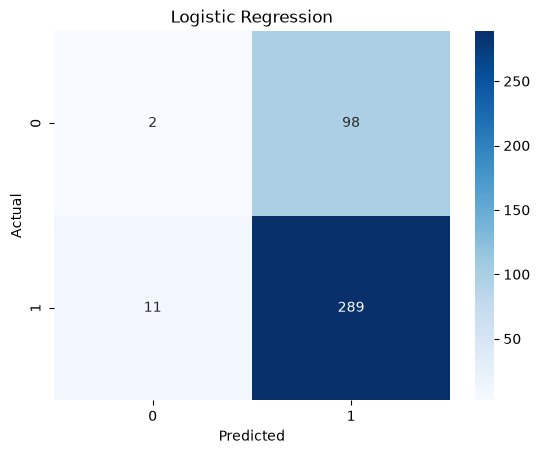

In [21]:
# confusion matrix for LR
cm_lr = confusion_matrix(y_test, pred_lr)
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues")
plt.title("Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


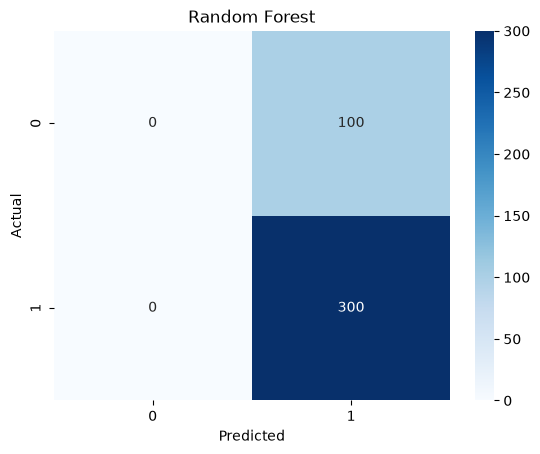

In [22]:
# confusion matrix for RF
cm_rf = confusion_matrix(y_test, pred_rf)
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

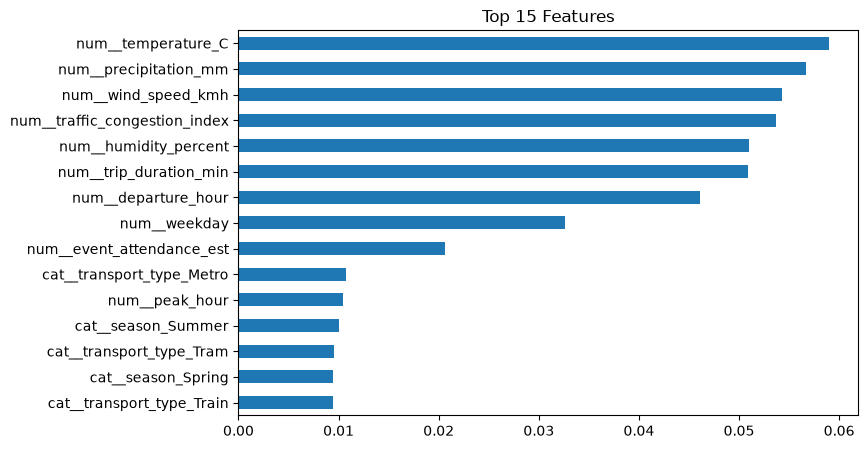

In [23]:
# which features matter most
feat_names = model_rf.named_steps["pre"].get_feature_names_out()
importances = model_rf.named_steps["clf"].feature_importances_

feat_imp = pd.Series(importances, index=feat_names).sort_values(ascending=False).head(15)

plt.figure(figsize=(8,5))
feat_imp.plot(kind="barh")
plt.title("Top 15 Features")
plt.gca().invert_yaxis()
plt.show()

In [24]:
# show some sample predictions
results = X_test.copy()
results["actual"] = y_test
results["predicted"] = pred_rf
results["prob_delayed"] = model_rf.predict_proba(X_test)[:,1].round(3)

# show a few correct and wrong predictions
print("Sample predictions:")
results[["actual", "predicted", "prob_delayed"]].head(10)

Sample predictions:


,actual,predicted,prob_delayed
1180,0,1,0.820
239,1,1,0.680
221,1,1,0.800
1740,1,1,0.755
1997,1,1,0.750
1085,0,1,0.810
1458,1,1,0.785
1463,1,1,0.820
1331,1,1,0.785
1685,1,1,0.735


In [ ]:
# since 75% of trips are delayed, the models above mostly just predict 1
# let's try class_weight='balanced' to handle the imbalance
model_lr_bal = Pipeline([
    ("pre", preprocessor),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

model_lr_bal.fit(X_train, y_train)
pred_lr_bal = model_lr_bal.predict(X_test)

print("Balanced Logistic Regression")
print("Accuracy:", accuracy_score(y_test, pred_lr_bal))
print("ROC AUC:", roc_auc_score(y_test, model_lr_bal.predict_proba(X_test)[:,1]))
print(classification_report(y_test, pred_lr_bal))

In [ ]:
# random forest with balanced class weights
model_rf_bal = Pipeline([
    ("pre", preprocessor),
    ("clf", RandomForestClassifier(n_estimators=200, max_depth=8, class_weight="balanced", random_state=42))
])

model_rf_bal.fit(X_train, y_train)
pred_rf_bal = model_rf_bal.predict(X_test)

print("Balanced Random Forest")
print("Accuracy:", accuracy_score(y_test, pred_rf_bal))
print("ROC AUC:", roc_auc_score(y_test, model_rf_bal.predict_proba(X_test)[:,1]))
print(classification_report(y_test, pred_rf_bal))

In [ ]:
# confusion matrix for balanced RF
cm_rf_bal = confusion_matrix(y_test, pred_rf_bal)
sns.heatmap(cm_rf_bal, annot=True, fmt="d", cmap="Blues")
plt.title("Balanced Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
# sample predictions from the balanced model
results_bal = X_test.copy()
results_bal["actual"] = y_test
results_bal["pred_rf_balanced"] = pred_rf_bal
results_bal["prob_delayed"] = model_rf_bal.predict_proba(X_test)[:, 1].round(3)

print("Sample Predictions (Balanced Random Forest):")
results_bal[["actual", "pred_rf_balanced", "prob_delayed"]].head(10)